# Laboratory 5 — Analysing Music and Speech

**CN240 Data Science for Signal Processing · SF251 Introduction to Data Science**
Week 5 · Semester 1, Academic Year 2026 · Dr Surasak Phetmanee

---

| | |
|---|---|
| **Name** | Ruth Benedicta Susanto |
| **Student ID** | 6710755239 |
| **Section** | 750001 |

## What you will do today

Every signal has a second face. Today you turn the FFT on four signals you already know —
a pure tone, a **mystery chord**, last week's walking data — and finish by drawing a
**spectrogram of speech**. Week 4's `find_peaks` comes along: today it reads *spectra*.

**Deliverables (due before week 6, pushed to your GitHub repository):**
1. **The chord, solved** — three frequencies (honest decimals!), three note names, one chord name
2. **The trade-off pair** — two spectrograms of the same speech, long vs short window, one sentence each
3. **One insight** — 2–3 sentences citing a number or picture from this lab

> **Honesty rule from the lecture:** report frequencies to no more decimals than Δf = fs/N justifies.
> A 3-second clip has Δf ≈ 0.33 Hz — so "440.0 Hz" is honest, "440.017 Hz" is fiction.


## Setup — run first, do not edit


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

plt.rcParams['figure.figsize'] = (12, 3.5)
plt.rcParams['axes.grid'] = True
print("NumPy", np.__version__)

NumPy 2.4.6


---
## Mission 1 — Warm-up: read 440 off your own axis

A pure 440 Hz tone (the note **A**, the orchestra's tuning fork), 3 seconds at 8000 Hz.
Slide 8's five lines, typed by you. If the peak lands anywhere except 440, an axis is wrong —
that is the lesson.


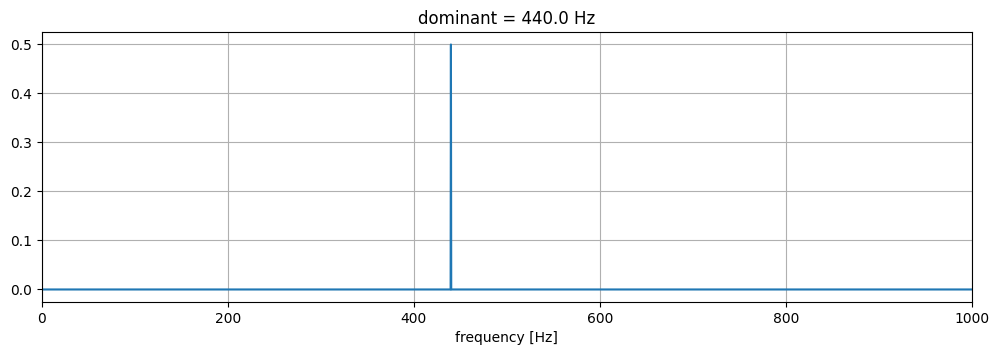

dominant frequency: 440.0 Hz   (Δf = 0.33 Hz)


In [2]:
FS_TONE = 8000
t_tone = np.arange(0, 3, 1 / FS_TONE)
tone = np.sin(2 * np.pi * 440 * t_tone)

def spectrum(x, fs):
    """Return (f, mag): the frequency axis in Hz and the magnitude spectrum."""
    # TODO (1.1): slide 8's recipe —
    N   = len(x)
    mag = np.abs(np.fft.rfft(x)) / N
    f   = np.fft.rfftfreq(N, 1/fs)
    return f, mag


out = spectrum(tone, FS_TONE)
if out is None:
    print("spectrum() not filled in yet")
else:
    f, mag = out
    f_dom = f[mag[1:].argmax() + 1]          # skip bin 0 — that's the mean
    plt.plot(f, mag); plt.xlim(0, 1000)
    plt.xlabel("frequency [Hz]"); plt.title(f"dominant = {f_dom:.1f} Hz")
    plt.show()
    print(f"dominant frequency: {f_dom:.1f} Hz   (Δf = {FS_TONE/len(tone):.2f} Hz)")

**Checkpoint:** the plot shows one spike, the title says **440.0 Hz** — one ingredient,
one line, exactly as slide 9 promised.


---
## Mission 2 — The mystery chord *(Deliverable 1)*

Three notes sound together for 3 seconds. Nobody tells you which.
Your week-4 tool reads your week-5 picture: **`find_peaks` on the spectrum.**


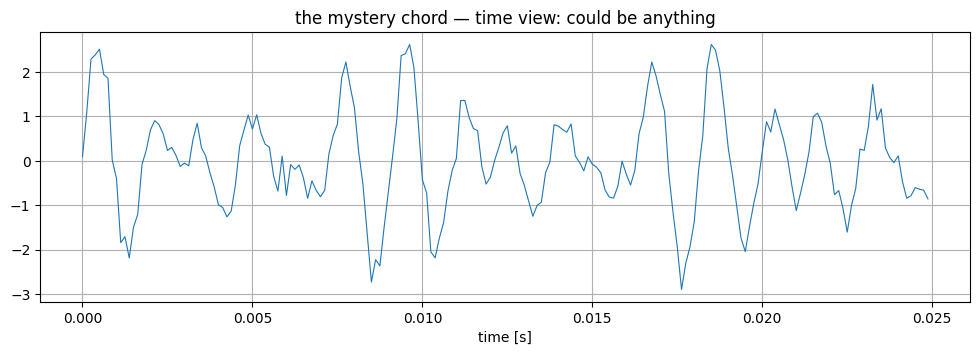

In [3]:
# --- The mystery chord (run once, do not edit — and no fair reading the code!) ---
rng = np.random.default_rng(240)
FS_CHORD = 8000
_tc = np.arange(0, 3, 1 / FS_CHORD)
_freqs_secret = [440.00, 554.37, 659.25]
_amps_secret = [1.0, 0.8, 0.9]
chord = sum(a * np.sin(2 * np.pi * fq * _tc) for fq, a in zip(_freqs_secret, _amps_secret))
chord = chord + 0.25 * rng.standard_normal(_tc.size)
plt.plot(_tc[:200], chord[:200], linewidth=0.8)
plt.title("the mystery chord — time view: could be anything")
plt.xlabel("time [s]"); plt.show()

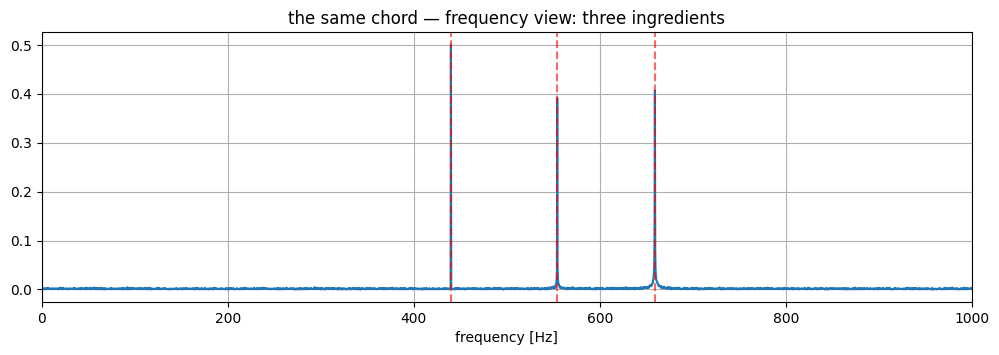

  440.0 Hz  ->  nearest note: A4 (440.0 Hz)
  554.3 Hz  ->  nearest note: C#5 (554.37 Hz)
  659.3 Hz  ->  nearest note: E5 (659.25 Hz)


In [4]:
NOTE_TABLE = {
    "G4": 392.00, "A4": 440.00, "B4": 493.88, "C5": 523.25,
    "C#5": 554.37, "D5": 587.33, "E5": 659.25, "F5": 698.46, "G5": 783.99,
}

if spectrum(chord, FS_CHORD) is None:
    print("finish Mission 1 first")
else:
    f, mag = spectrum(chord, FS_CHORD)

    # TODO (2.1): find the three tallest spectral lines
    idx, _ = find_peaks(mag, prominence=0.05)     # peaks ON THE SPECTRUM
    #   then keep the three with the largest mag[idx] and read their f[idx]
    top3 = idx[np.argsort(mag[idx])[-3:]]
    note_freqs = f[top3]

    if note_freqs is None:
        print("2.1 not filled in yet")
    else:
        plt.plot(f, mag); plt.xlim(0, 1000); plt.xlabel("frequency [Hz]")
        for fq in sorted(note_freqs):
            plt.axvline(fq, color="red", linestyle="--", alpha=0.6)
        plt.title("the same chord — frequency view: three ingredients")
        plt.show()
        for fq in sorted(note_freqs):
            name = min(NOTE_TABLE, key=lambda k: abs(NOTE_TABLE[k] - fq))
            print(f"{fq:7.1f} Hz  ->  nearest note: {name} ({NOTE_TABLE[name]} Hz)")

**Q1 — name that chord:** write the three frequencies (honest decimals), the three note names,
and the chord they spell. *(A hint from music theory: root, major third, perfect fifth.)*
Could you have answered ANY of this from the time-view plot above?

*440.0 Hz, A4. 554.3 Hz, C#5. 659.3 Hz, E5*


---
## Mission 3 — The promise check: last week's numbers become lines

Week 4 measured a walking cadence of **108 steps/min** by counting peaks, and a heart rate of
**~110 bpm** on the arrhythmic MIT-BIH patient. The lecture promised both would reappear as
spectral lines. Time to collect.


In [5]:
# --- Lab 4's walking recording, regenerated (run once, do not edit) ----------
FSA = 50
rng_a = np.random.default_rng(240)
ta = np.arange(0, 60, 1 / FSA)
swing = np.sin(2 * np.pi * 0.9 * ta)
az_g = 1.0 + 0.30 * np.abs(np.sin(np.pi * 1.8 * ta)) ** 8 + 0.05 * rng_a.standard_normal(ta.size)
print("walking az_g ready:", az_g.size, "samples at", FSA, "Hz")

walking az_g ready: 3000 samples at 50 Hz


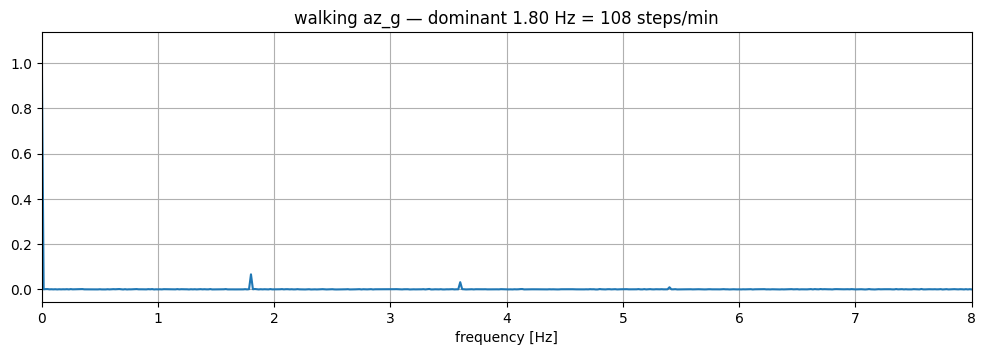

dominant: 1.80 Hz -> cadence 108 steps/min (week 4 counted 108 by peaks)
Look right of the main line: 3.6 and 5.4 Hz — the harmonics, as slide 9 promised.


In [6]:
if spectrum(az_g, FSA) is None:
    print("finish Mission 1 first")
else:
    f, mag = spectrum(az_g, FSA)
    # TODO (3.1): dominant frequency, skipping bin 0
    #   (bin 0 holds the MEAN — for az_g that is gravity, ~1 g, and it would win by a mile)
    f_walk = f[mag[1:].argmax() + 1]
    if f_walk is None:
        print("3.1 not filled in yet")
    else:
        plt.plot(f, mag); plt.xlim(0, 8); plt.xlabel("frequency [Hz]")
        plt.title(f"walking az_g — dominant {f_walk:.2f} Hz = {f_walk*60:.0f} steps/min")
        plt.show()
        print(f"dominant: {f_walk:.2f} Hz -> cadence {f_walk*60:.0f} steps/min "
              f"(week 4 counted 108 by peaks)")
        print("Look right of the main line: 3.6 and 5.4 Hz — the harmonics, as slide 9 promised.")

In [7]:
# Optional but satisfying: the ECG's turn (downloads the MIT-BIH excerpt as in Labs 3-4)
try:
    from scipy.datasets import electrocardiogram
    FS_ECG = 360
    ecg = electrocardiogram()[:60 * FS_ECG]
    # Week 3, still earning its keep: without this detrend, the baseline wander
    # (~0.55 Hz) is the tallest line in the band and the "heart rate" comes out at 33 bpm!
    ecg = ecg - np.convolve(ecg, np.ones(FS_ECG) / FS_ECG, mode="same")
    ecg = (ecg - ecg.mean()) / ecg.std()
    if spectrum(ecg, FS_ECG) is not None:
        f, mag = spectrum(ecg, FS_ECG)
        band = (f > 0.5) & (f < 3.0)                 # look where heart rates live
        f_heart = f[band][mag[band].argmax()]
        print(f"strongest rhythm in 0.5-3 Hz: {f_heart:.2f} Hz  ->  {f_heart*60:.0f} bpm")
        print("(week 4's find_peaks said ~110 bpm — two independent instruments, one truth)")
    else:
        print("finish Mission 1 first")
except Exception as e:
    print("ECG download unavailable here — fine, the walking check above is the deliverable:", e)

strongest rhythm in 0.5-3 Hz: 1.87 Hz  ->  112 bpm
(week 4's find_peaks said ~110 bpm — two independent instruments, one truth)


**Q2 — two instruments:** `find_peaks` (time domain) and the FFT (frequency domain) measured the
same cadence and the same heart rate. They share no code — so *why* must they agree? And which would
you trust more if the recording were only 5 seconds long? *(Hint: Δf = fs/N.)*

Find_peaks and FFT agree because they measure the same repeating heartbeat in different ways. find_peaks measures the time between heartbeats, while FFT finds the heartbeat's frequency. Therefore, HR = 60f. Here, find_peaks gives about 110 bpm and FFT gives 1.87 Hz = 112 bpm.

For only 5 seconds, I would trust find_peaks more because FFT has lower frequency resolution. With fs = 360 Hz and N = 1800, Δf = fs/N = 0.2 Hz, which equals 12 bpm per FFT bin. So the FFT estimate is relatively coarse for such a short recording.



---
## Mission 4 — The speech portrait *(Deliverable 2)*

Upload **`speech.wav`** from Lab 2 (Files pane → upload). No file? The cell synthesises a
speech-like utterance instead, so everything still runs.


In [8]:
# --- Load speech.wav, or synthesise a stand-in (run once, do not edit) --------
try:
    from scipy.io import wavfile
    FS_SP, sp = wavfile.read("speech.wav")
    sp = sp.astype(float) / np.abs(sp).max()
    SP_SOURCE = "speech.wav (Lab 2)"
except Exception:
    FS_SP = 8000
    _ts = np.arange(0, 3, 1 / FS_SP)
    _pitch = 140 + 40 * np.sin(2 * np.pi * 0.5 * _ts)          # rising-falling intonation
    _phase = 2 * np.pi * np.cumsum(_pitch) / FS_SP
    sp = sum((0.5 / k) * np.sin(k * _phase) for k in range(1, 6))   # harmonics
    _burst = (np.sin(2 * np.pi * 1.0 * _ts) > 0.95)                 # a "consonant" burst
    sp = sp + 0.8 * _burst * np.random.default_rng(0).standard_normal(_ts.size)
    SP_SOURCE = "synthetic stand-in"
print(f"speech loaded: {SP_SOURCE} — {len(sp)/FS_SP:.1f} s at {FS_SP} Hz")

speech loaded: synthetic stand-in — 3.0 s at 8000 Hz


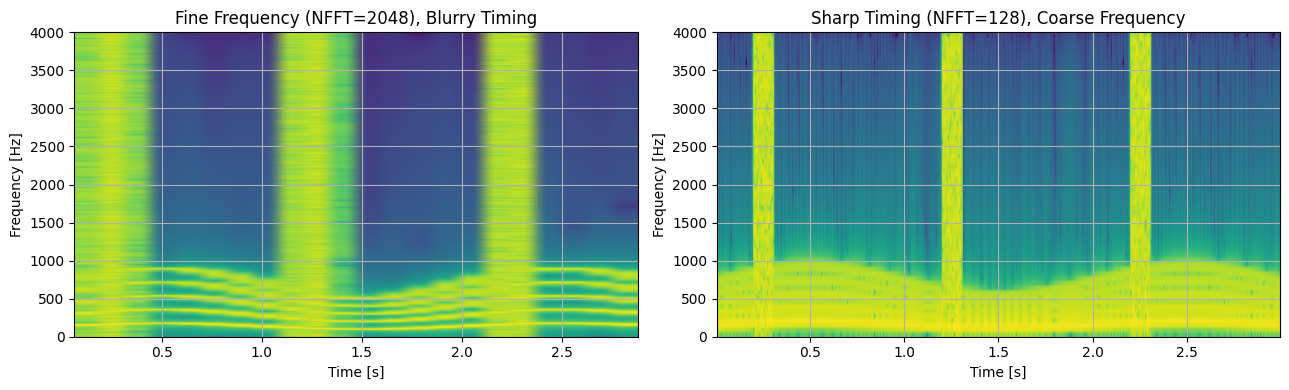

In [9]:
# TODO (4.1): the trade-off pair — the SAME sound, two window lengths
# Draw both (two subplots), label which is which.

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
done_4_1 = True
# --- your two specgram calls here (use axes[0].specgram / axes[1].specgram) ---
axes[0].specgram(sp, NFFT=2048, Fs=FS_SP, noverlap=2048 // 2)
axes[0].set_title('Fine Frequency (NFFT=2048), Blurry Timing')
axes[0].set_xlabel('Time [s]')
axes[0].set_ylabel('Frequency [Hz]')

axes[1].specgram(sp, NFFT=128, Fs=FS_SP, noverlap=128 // 2)
axes[1].set_title('Sharp Timing (NFFT=128), Coarse Frequency')
axes[1].set_xlabel('Time [s]')
axes[1].set_ylabel('Frequency [Hz]')

plt.tight_layout()
plt.show()

if not done_4_1:
    plt.close(fig)
    print("4.1 not filled in yet — set done_4_1 = True when your two spectrograms draw")

**Q3 — read your own portrait:** on the long-window spectrogram, what do the horizontal stripes
represent, and what happens to them where the pitch changes? On the short-window one, what became
clearer and what was lost? One sentence per picture — that pair of sentences is part of Deliverable 2.

In the long-window spectrogram, the horizontal stripes represent the fundamental pitch and its harmonics, which move up or down together when the pitch changes.

In the short-window spectrogram, the timing of pitch changes becomes clearer and sharper, but the frequency and harmonic details become less precise.


---
## Stretch goals (optional, recommended)

**S1 — spectral centroid** *(next week's feature, early)*: `np.sum(f * mag) / np.sum(mag)` —
compute it for the tone, the chord and the speech. Which is "brightest", and does the ranking
match your ear?

**S2 — aliasing, revisited**: take every 8th sample of the chord (`chord[::8]`, so fs → 1000 Hz)
and re-run Mission 2's detector. Week 2 warned you what happens to frequencies above the new
Nyquist (500 Hz) — now watch a real note fold.


In [10]:
# TODO (S1 / S2)
def spectral_centroid(x, fs):
    f, mag = spectrum(x, fs)
    total = np.sum(mag)
    if total == 0:
        return np.nan
    return np.sum(f * mag) / total

signals = {
    "Pure tone (440 Hz)": (tone, FS_TONE),
    "Mystery chord": (chord, FS_CHORD),
    "Speech signal": (sp, FS_SP),
}

print("S1 — Spectral centroid")
centroids = {}
for label, (x, fs) in signals.items():
    centroids[label] = spectral_centroid(x, fs)
    print(f"{label}: {centroids[label]:.1f} Hz")

print("\nBrightness ranking (lowest to highest centroid):")
for label, value in sorted(centroids.items(), key=lambda item: item[1]):
    print(f"{label}: {value:.1f} Hz")

# Stretch goal S2 — aliasing after downsampling by a factor of 8.
# The new sampling rate is 8000/8 = 1000 Hz, so Nyquist = 500 Hz.
aliased = chord[::8]
FS_ALIAS = FS_CHORD / 8
f_alias, mag_alias = spectrum(aliased, FS_ALIAS)

alias_peaks, _ = find_peaks(mag_alias, prominence=0.05)
alias_peaks = alias_peaks[(f_alias[alias_peaks] > 0) & (f_alias[alias_peaks] < FS_ALIAS / 2)]
top_alias = alias_peaks[np.argsort(mag_alias[alias_peaks])[-3:]]
top_alias = top_alias[np.argsort(f_alias[top_alias])]

print("\nS2 — Aliasing after taking every 8th sample")
print(f"New sampling rate: {FS_ALIAS:.0f} Hz; Nyquist frequency: {FS_ALIAS/2:.0f} Hz")
print(f"Frequency resolution: {FS_ALIAS/len(aliased):.2f} Hz")
for idx in top_alias:
    print(f"Observed peak: {f_alias[idx]:.1f} Hz")

print("Expected folding: 440 Hz stays near 440 Hz; 554.37 Hz folds to about 445.63 Hz;")
print("659.25 Hz folds to about 340.75 Hz because frequencies above Nyquist reflect below 500 Hz.")

S1 — Spectral centroid
Pure tone (440 Hz): 440.0 Hz
Mystery chord: 1816.6 Hz
Speech signal: 1531.2 Hz

Brightness ranking (lowest to highest centroid):
Pure tone (440 Hz): 440.0 Hz
Speech signal: 1531.2 Hz
Mystery chord: 1816.6 Hz

S2 — Aliasing after taking every 8th sample
New sampling rate: 1000 Hz; Nyquist frequency: 500 Hz
Frequency resolution: 0.33 Hz
Observed peak: 340.7 Hz
Observed peak: 440.0 Hz
Observed peak: 445.7 Hz
Expected folding: 440 Hz stays near 440 Hz; 554.37 Hz folds to about 445.63 Hz;
659.25 Hz folds to about 340.75 Hz because frequencies above Nyquist reflect below 500 Hz.


---
## Deliverable 3 — one insight

*2–3 sentences: something today's frequency view revealed that four weeks of time-domain work
never showed — cite the number or the picture.*

The time-view plot of the mystery chord looked like unreadable noise "could be anything." The frequency view resolved it into three clean, unambiguous lines at 440.0, 554.3, and 659.3 Hz (A4, C#5, E5), something no amount of squinting at the waveform could have named.

---
## Before you submit (checklist)

- [ ] Whole notebook runs top to bottom — **Runtime → Restart and run all must pass**
- [ ] Mission 1: the spike sits at 440.0 Hz on your own axis
- [ ] Mission 2: three frequencies, three notes, one chord named (Deliverable 1)
- [ ] Mission 3: the cadence line found; ECG check run if the download works
- [ ] Mission 4: the trade-off pair drawn and captioned (Deliverable 2)
- [ ] Q1–Q3 answered + the insight written (Deliverable 3)
- [ ] Pushed to your GitHub repository

*Next week: **Feature Engineering** — time features (week 4) + frequency features (today) fuse into
sliding-window feature matrices, and the Human Activity Recognition lab begins. Two deadlines land
next week: **Assignment 1** and the **dataset milestone**. Come with both.*
